In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.ticker import FormatStrFormatter
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report,
                             precision_recall_curve, average_precision_score)

In [17]:
def model_metrics(model_path, csv_path, batch_size=18, threshold=0.5):
    model = tf.keras.models.load_model(model_path)
    print('Model input shape :', model.input_shape)
    print('Model output shape:', model.output_shape)

    # Load the CSV and build integer labels (0 = negative, 1 = positive)
    df = pd.read_csv(csv_path)
    paths = df['path'].astype(str).tolist()

    # set ground truth labels to y_true
    labels = df['diagnosis']
    y_true = labels.values.astype(int)

    missing = [p for p in paths if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError(f'{len(missing)} image paths not found, e.g. {missing[:3]}')
    print(f'{len(paths)} images | class counts: {np.bincount(y_true)}')

    # tf.data pipeline: read -> decode -> resize -> -> batch
    def load_image(path):
        img = tf.io.read_file(path)
        img = tf.io.decode_image(img, channels=3, expand_animations=False)
        img = tf.cast(img, tf.float32)
        #img.set_shape((224, 224) + (3,))
        return img

    ds = (tf.data.Dataset.from_tensor_slices(paths).map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE))

    # model predictions on test images
    y_prob = model.predict(ds).ravel()
    print('Prediction shape:', y_prob.shape)

    # thresholding
    y_pred = (y_prob >= threshold).astype(int)

    # getting metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auc = roc_auc_score(y_true, y_prob)

    # classification report and confusion matrix
    cls_report = classification_report(y_true, y_pred, zero_division=0)
    print(cls_report)
    conf_mat = confusion_matrix(y_true, y_pred)
    print('Confusion matrix (rows = true, cols = predicted):')
    print(conf_mat)

    # generate ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.show()

    # precision-recall curve with the no-skill baseline as the bottom of the y-axis
    precision_curve, recall_curve, _ = precision_recall_curve(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)
    baseline = y_true.mean()

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(recall_curve, precision_curve, label=f'AP = {ap:.3f}')
    ax.axhline(baseline, color='k', linestyle='--', label=f'No skill ({baseline:.2f})')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title('Precision-Recall Curve')
    ax.set_xlim(0, 1)
    ax.set_ylim(baseline, 1.02)

    # baseline tick + round ticks, skipping any that sit too close to the baseline
    round_ticks = [t for t in np.arange(0.1, 1.01, 0.1) if t - baseline > 0.03]
    ax.set_yticks([baseline] + round_ticks)
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    ax.legend(loc='upper right')
    plt.show()

    results = pd.DataFrame({'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC', 'Avg Precision'],
                            'Value': [acc, prec, rec, f1, auc, ap]})

    return results, conf_mat, cls_report, y_true, y_prob

Model input shape : (None, 224, 224, 3)
Model output shape: (None, 1)
2577 images | class counts: [ 778 1799]


error: operand #1 does not dominate this use
E0000 00:00:1795399268.769783 9506194 meta_optimizer.cc:967] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
W0000 00:00:1795399268.792917 9506194 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
=== Source Location Trace: === 
tensorflow/core/grappler/optimizers/tfg_optimizer_hook.cc:149



143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step

error: operand #1 does not dominate this use
W0000 00:00:1795399293.852427 9506194 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
=== Source Location Trace: === 
tensorflow/core/grappler/optimizers/tfg_optimizer_hook.cc:149



144/144 ━━━━━━━━━━━━━━━━━━━━ 26s 172ms/step
Prediction shape: (2577,)
              precision    recall  f1-score   support

           0       0.55      0.66      0.60       778
           1       0.84      0.77      0.80      1799

    accuracy                           0.74      2577
   macro avg       0.70      0.71      0.70      2577
weighted avg       0.75      0.74      0.74      2577

Confusion matrix (rows = true, cols = predicted):
[[ 510  268]
 [ 413 1386]]


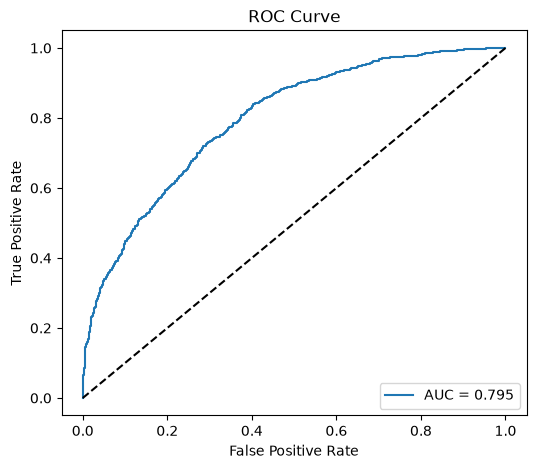

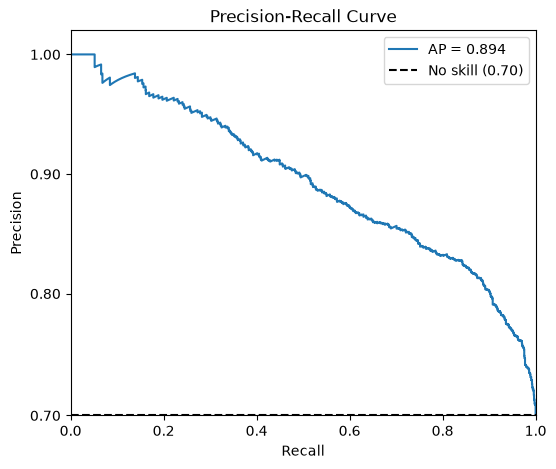

In [18]:
nonGWO_results, nonGWO_confusionmatrix, nonGWO_clsreport, nonGWO_ytrue, nonGWO_yprob = model_metrics(
    model_path='../output/nonGWO_model.keras', csv_path='../working/test.csv')
# GWO_results, GWO_confusionmatrix, GWO_clsreport, GWO_ytrue, GWO_yprob = model_metrics(
#     model_path='../output/GWO_model.keras', csv_path='../working/test.csv')

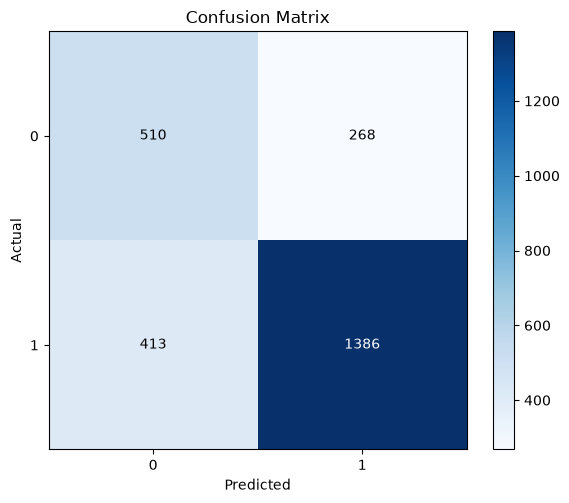

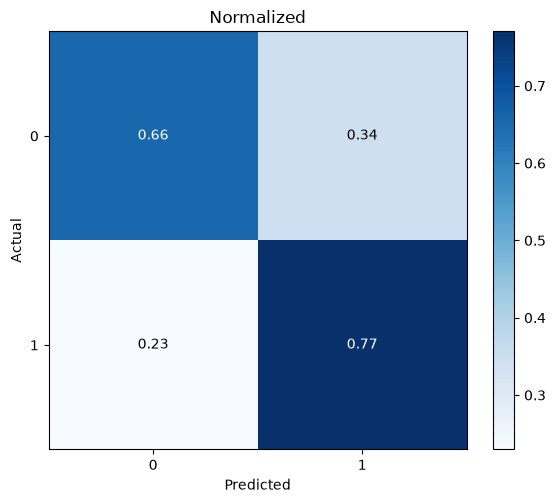

In [19]:
def plot_confusion_matrix(cm, labels=None, normalize=False, title="Confusion Matrix", cmap="Blues"):
    cm = np.array(cm)
    if normalize:
        cm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    n = cm.shape[0]
    labels = labels or list(range(n))

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap=cmap)
    fig.colorbar(im, ax=ax)

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)

    # Annotate each cell, switching text color for contrast
    thresh = cm.max() / 2
    for i in range(n):
        for j in range(n):
            text = f"{cm[i, j]:.2f}" if normalize else f"{cm[i, j]}"
            ax.text(j, i, text, ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.show()

cm = nonGWO_confusionmatrix

plot_confusion_matrix(cm, labels=[0, 1])
plot_confusion_matrix(cm, labels=[0, 1], normalize=True, title="Normalized")